# Random Forests vs Gradient Boosting on Breast Cancer

Random forest and gradient boosting are trained and compared with a leak-free protocol:

- stratified 80/20 split; the **test set is used once** for the final report,
- tree ensembles are scale-invariant, so no scaler is used,
- comparison against a majority-class baseline, a single tree and a bagging model with **repeated stratified CV** (mean ± std) on the training data,
- feature importance reported two ways (impurity and permutation),
- the number of boosting stages is judged on a validation split taken **from the training data**, not on the test set.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (BaggingClassifier, GradientBoostingClassifier, RandomForestClassifier)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid")

In [2]:
# Load and prepare the data
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

# Stratified split; X_test / y_test stay untouched until the final evaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## 2. Random Forests



**Random Forest** is an extension of Bagging that introduces an extra layer of randomness.

### Key Difference from Bagging:
- While Bagging uses full feature set per split, **Random Forests use a random subset of features** for each split in the tree.

### Advantages:
- Further reduces correlation between base learners.
- Performs automatic feature selection.
- Reduces overfitting compared to single Decision Tree.

### Mathematical Difference:
In Random Forest:
- At each node, a random subset of features of size $m \leq M$ is considered.
- For classification, typically $m = \sqrt{M}$
- For regression, $m = M/3$

This random feature selection reduces correlation $\rho$ between trees, which further reduces ensemble variance.


In [3]:
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
gb_clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)

## Cross-validated comparison (training data only)

Repeated 5-fold stratified CV (25 fits per model) with accuracy and ROC-AUC. The spread (`std`) is as important as the mean: on 455 training rows, differences smaller than the std are not reliable.

In [4]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)
models = {
    'majority baseline': DummyClassifier(strategy='most_frequent'),
    'single decision tree': DecisionTreeClassifier(random_state=42),
    'bagging (100 trees)': BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42), n_estimators=100, random_state=42, n_jobs=-1),
    'random forest': rf_clf,
    'gradient boosting': gb_clf,
}
rows = {}
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=['accuracy', 'roc_auc'])
    rows[name] = {'accuracy': f"{r['test_accuracy'].mean():.3f} ± {r['test_accuracy'].std():.3f}",
                  'roc_auc': f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}"}
pd.DataFrame(rows).T

,accuracy,roc_auc
majority baseline,0.626 ± 0.000,0.500 ± 0.000
single decision tree,0.929 ± 0.016,0.925 ± 0.021
bagging (100 trees),0.953 ± 0.023,0.988 ± 0.010
random forest,0.957 ± 0.019,0.990 ± 0.009
gradient boosting,0.957 ± 0.022,0.991 ± 0.008


## Random Forest: fit on the training set, evaluate on the test set

In [5]:
rf_clf.fit(X_train, y_train)
y_pred_rf = rf_clf.predict(X_test)

print("Accuracy (Random Forest):", round(accuracy_score(y_test, y_pred_rf), 4))
print(classification_report(y_test, y_pred_rf))

Accuracy (Random Forest): 0.9561
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



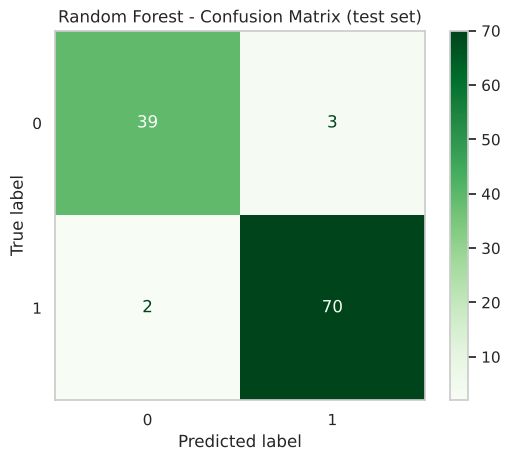

In [6]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=rf_clf.classes_)
disp_rf.plot(cmap='Greens')
plt.title("Random Forest - Confusion Matrix (test set)")
plt.grid(False)
plt.show()

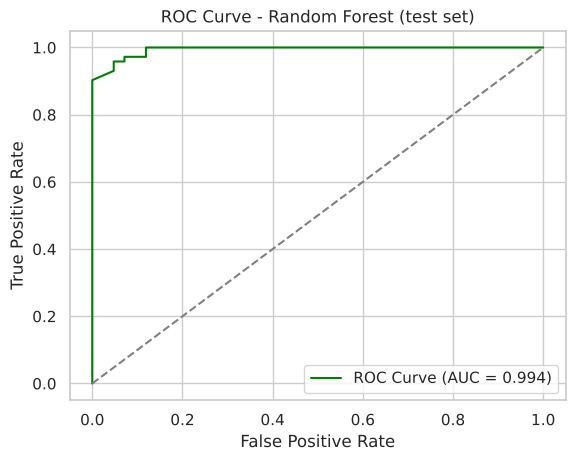

In [7]:
y_score_rf = rf_clf.predict_proba(X_test)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_score_rf)
roc_auc_rf = roc_auc_score(y_test, y_score_rf)

plt.figure()
plt.plot(fpr_rf, tpr_rf, color='green', label=f'ROC Curve (AUC = {roc_auc_rf:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.title('ROC Curve - Random Forest (test set)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

### Feature importance: impurity vs permutation

Impurity-based importance is computed from the training data and is biased towards features with many possible split points (and, with correlated features such as *radius / perimeter / area*, it splits credit arbitrarily between them). **Permutation importance on held-out data** measures how much test accuracy drops when a feature is shuffled; correlated features can still mask each other, so read the two as complementary.

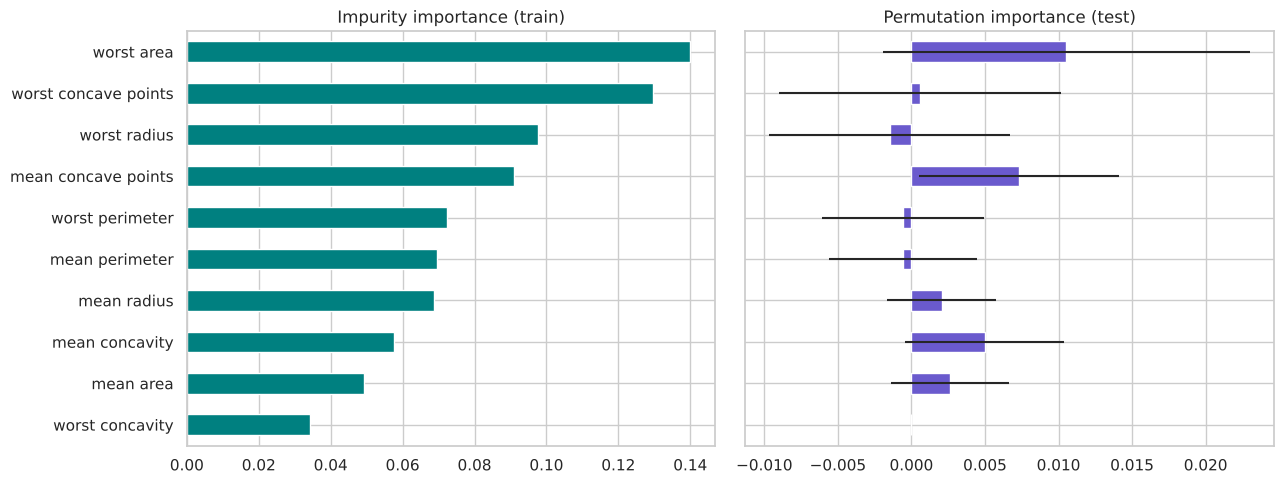

In [8]:
imp_impurity = pd.Series(rf_clf.feature_importances_, index=X.columns)
perm = permutation_importance(rf_clf, X_test, y_test, n_repeats=30, random_state=0, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=X.columns)

top = imp_impurity.sort_values(ascending=False).head(10).index
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
imp_impurity[top][::-1].plot.barh(ax=axes[0], color='teal', title='Impurity importance (train)')
imp_perm[top][::-1].plot.barh(ax=axes[1], xerr=pd.Series(perm.importances_std, index=X.columns)[top][::-1],
                              color='slateblue', title='Permutation importance (test)')
plt.tight_layout(); plt.show()

### Interpretation: Random Forest

- Random forests decorrelate trees by choosing a random feature subset at every split, which usually generalises better than plain bagging at the same number of trees.
- The two charts only partly agree: impurity importance spreads credit over the correlated size features (area / radius / perimeter), while permutation importance on held-out data is near zero for most of them (shuffling one is compensated by its correlated twins) and singles out only a few, such as *worst area* and *mean concave points*. Neither measure is causal, and with 114 test rows the permutation values are small and noisy.
- Whether the forest beats bagging *here* is a question for the CV table above, not for the test-set score of one split.

### Bagging vs Random Forests

| Feature                  | Bagging                         | Random Forests                  |
|--------------------------|----------------------------------|----------------------------------|
| Feature Subsets          | All features                    | Random subset at each split     |
| Tree Correlation         | Higher                          | Lower                           |
| Overfitting Risk         | Slightly higher                 | Lower                           |
| Interpretability         | Medium                          | Medium                          |
| Feature Importance       | No                              | Yes                             |


### Summary: Random Forest

Let’s extend the “asking friends” analogy:

- Now, instead of just asking the same question to 10 friends, you ask **different types of questions** to each one — like genre, mood, time of day, etc.
- This adds **diversity** in their answers, reducing the chance they all recommend the same type of movie.

That’s what Random Forest does:
- It builds many **randomized decision trees**.
- Each tree sees different data **and** different features.
- Their combined result is more stable and robust.

It's like having a **committee of experts**, each looking at the problem from a slightly different angle.


## 3. Boosting: Gradient Boosting



**Boosting** is an ensemble method that combines weak learners **sequentially**. Each learner tries to correct the mistakes of the previous one.

### Gradient Boosting:
- It builds trees **one after another**, minimizing a **loss function** using gradient descent.
- Instead of training independently like Bagging, each tree focuses on residuals of previous model.

### Intuition:
Let $F_0(x)$ be the initial prediction (e.g., mean for regression).
Each iteration:
1. Compute pseudo-residuals: $r_i = -\frac{\partial L(y_i, F(x_i))}{\partial F(x_i)}$
2. Fit tree $h_m(x)$ to $r$
3. Update model: $F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$

Where:
- $\eta$ = learning rate
- $L$ = loss function (e.g., log loss or MSE)

### Key Characteristics:
- Reduces both bias and variance.
- Can overfit if too many trees or low regularization.


## Gradient Boosting: fit on the training set, evaluate on the test set

In [9]:
gb_clf.fit(X_train, y_train)
y_pred_gb = gb_clf.predict(X_test)

print("Accuracy (Gradient Boosting):", round(accuracy_score(y_test, y_pred_gb), 4))
print(classification_report(y_test, y_pred_gb))

Accuracy (Gradient Boosting): 0.9561
              precision    recall  f1-score   support

           0       0.97      0.90      0.94        42
           1       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



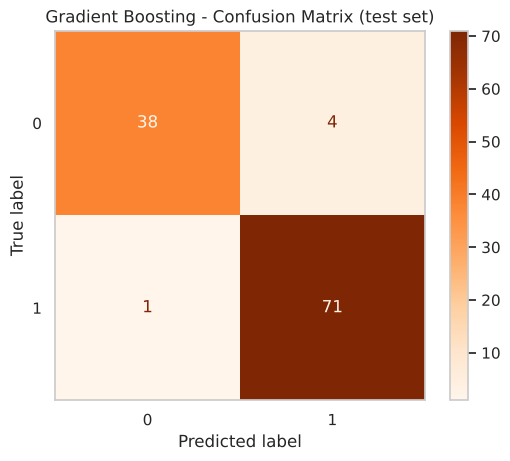

In [10]:
cm_gb = confusion_matrix(y_test, y_pred_gb)
disp_gb = ConfusionMatrixDisplay(confusion_matrix=cm_gb, display_labels=gb_clf.classes_)
disp_gb.plot(cmap='Oranges')
plt.title("Gradient Boosting - Confusion Matrix (test set)")
plt.grid(False)
plt.show()

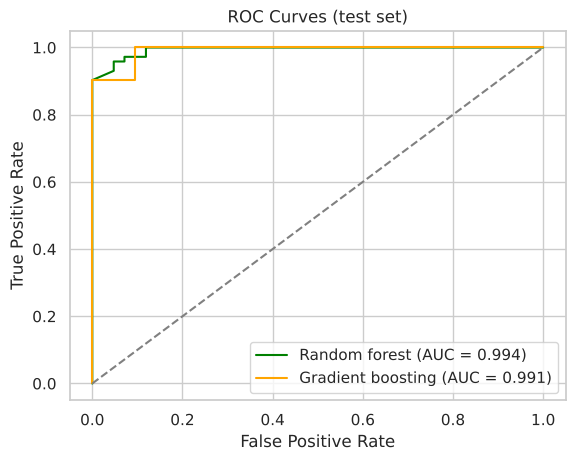

In [11]:
y_score_gb = gb_clf.predict_proba(X_test)[:, 1]
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_score_gb)
roc_auc_gb = roc_auc_score(y_test, y_score_gb)

plt.figure()
plt.plot(fpr_rf, tpr_rf, color='green', label=f'Random forest (AUC = {roc_auc_rf:.3f})')
plt.plot(fpr_gb, tpr_gb, color='orange', label=f'Gradient boosting (AUC = {roc_auc_gb:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.title('ROC Curves (test set)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

### How many boosting stages? (validation split from the training data)

Boosting can over-fit as stages are added. To see it without touching the test set, the training data is split once more into fit / validation parts and log-loss is tracked per stage. The test set plays no role in this choice.

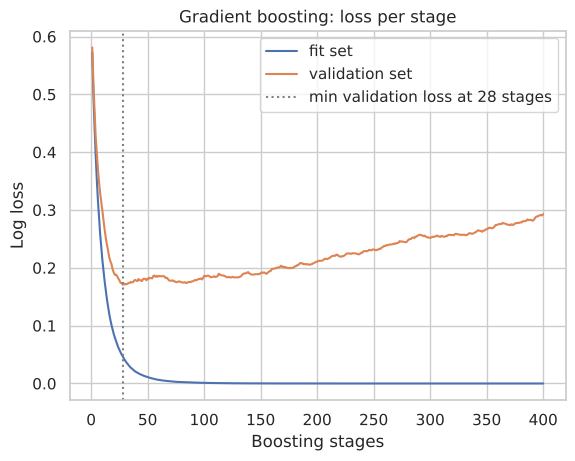

In [12]:
from sklearn.metrics import log_loss

X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=1, stratify=y_train)
gb_long = GradientBoostingClassifier(n_estimators=400, learning_rate=0.1, random_state=42).fit(X_fit, y_fit)

fit_loss = [log_loss(y_fit, p) for p in gb_long.staged_predict_proba(X_fit)]
val_loss = [log_loss(y_val, p) for p in gb_long.staged_predict_proba(X_val)]
best = int(np.argmin(val_loss)) + 1

plt.plot(range(1, 401), fit_loss, label='fit set')
plt.plot(range(1, 401), val_loss, label='validation set')
plt.axvline(best, color='gray', linestyle=':', label=f'min validation loss at {best} stages')
plt.xlabel('Boosting stages'); plt.ylabel('Log loss'); plt.legend(); plt.title('Gradient boosting: loss per stage')
plt.show()

### Interpretation: Gradient Boosting

- **Higher ROC AUC** indicates precise learning of decision boundaries.
- **Often beats Bagging/RF** in accuracy with proper tuning.
- **Risks**: Gradient Boosting is prone to **overfitting** if too many trees or a high learning rate are used.

> Gradient Boosting trades off more training time and complexity for typically **better predictive performance**.


### Summary: Gradient Boosting

Imagine you're teaching a child to solve math problems.

- The child gets the first few problems wrong.
- Instead of restarting, you help them **focus only on the mistakes**.
- Over time, they get better and better because each lesson **corrects the errors from the previous one**.

That’s Gradient Boosting:
- It builds one model at a time.
- Each new model **focuses on fixing the mistakes** made by the previous ones.
- This results in a powerful final model that’s very good at capturing patterns.

Boosting is like **step-by-step tutoring** where every next step learns from previous failures.


## Comparative Summary

| Technique         | Learner Type    | Model Building | Handles Bias | Handles Variance | Overfitting Risk |
|------------------|------------------|----------------|---------------|------------------|------------------|
| Bagging           | Parallel         | Independent     | No             | Yes                | Low              |
| Random Forest     | Parallel         | Independent     | No             | Yes              | Lower            |
| Gradient Boosting | Sequential       | Dependent       | Yes           | Yes                | Medium–High      |

- **Bagging** is best for variance reduction (unstable models).
- **Random Forest** improves Bagging by decorrelating trees.
- **Gradient Boosting** is more aggressive and effective but can overfit without tuning.


## Methodology notes

- **Evaluation:** model comparison uses repeated stratified CV on the training split; the test set is used once for the per-model reports above. With 114 test rows, one patient is about 0.9 points, so test-score differences between the ensembles are not conclusive.
- **Baselines:** a majority classifier (≈63 %) and a single tree are included so the benefit of ensembling is visible.
- **No scaling:** tree ensembles are invariant to monotone feature scaling.
- **Tuning:** hyper-parameters are library defaults except for the illustrative learning-rate / stage count. A client project would tune them with nested CV (see the cross-validation project).
- **Generality:** the breast-cancer dataset is easy; ranking of methods may differ on noisier, larger or imbalanced data.